# Error-related negativity: does one trial of EEG tell us a mistake happened?

**Author:** Juliet Chinenye Duru · part of [shared-agency-search](https://github.com/JulietChinenyeDuru/shared-agency-search)

The shared-agency prototype treats neural signals as *uncertain evidence*: they may raise risk slightly, but never trigger an AI action on their own (principle P6). This notebook checks that idea against real EEG.

It uses the **ERP CORE Flankers task** (Kappenman et al., 2021), where people press left or right to the direction of a central arrow and sometimes make errors. It asks the same question as RQ1 in my PhD proposal, on a small scale:

> Does EEG predict an error **beyond** behaviour alone?

Steps:
1. Load one participant's recording (downloaded automatically by MNE).
2. Clean it: filter, re-reference, remove eye blinks with ICA.
3. Label every response as correct or error.
4. Average the brain response after errors and after correct responses: the **error-related negativity (ERN)** should appear at FCz within about 100 ms.
5. Predict errors **trial by trial** from (a) reaction time only, (b) EEG only, (c) both, with cross-validation.

In [1]:
# I install and import the libraries this notebook needs
# !pip install mne scikit-learn matplotlib pandas   # uncomment on first run
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve

mne.set_log_level("WARNING")
RNG = 42
print("MNE", mne.__version__)

MNE 1.13.2


## 1 Load the data

MNE downloads a small ERP CORE sample (one participant, Flankers task) to `~/mne_data` the first time. Set `RAW_PATH` to a file of your own to use other data.

In [2]:
# I load the ERP CORE Flankers recording (downloading it on first run) and list its event labels
RAW_PATH = None  # or a path to your own .fif file

if RAW_PATH is None:
    data_dir = mne.datasets.erp_core.data_path()
    RAW_PATH = data_dir / "ERP-CORE_Subject-001_Task-Flankers_eeg.fif"

raw = mne.io.read_raw(RAW_PATH, preload=True)
print(raw)
print("Channels:", raw.ch_names)
print("Event labels:", pd.Series(raw.annotations.description).value_counts().to_dict())

<Raw | ERP-CORE_Subject-001_Task-Flankers_eeg.fif, 33 x 935936 (914.0 s), ~235.7 MiB, data loaded>
Channels: ['FP1', 'F3', 'F7', 'FC3', 'C3', 'C5', 'P3', 'P7', 'P9', 'PO7', 'PO3', 'O1', 'Oz', 'Pz', 'CPz', 'FP2', 'Fz', 'F4', 'F8', 'FC4', 'FCz', 'Cz', 'C4', 'C6', 'P4', 'P8', 'P10', 'PO8', 'PO4', 'O2', 'HEOG_left', 'HEOG_right', 'VEOG_lower']
Event labels: {'response/left': 202, 'response/right': 200, 'stimulus/compatible/target_left': 100, 'stimulus/incompatible/target_right': 100, 'stimulus/incompatible/target_left': 100, 'stimulus/compatible/target_right': 100}


## 2 Clean the signal

- **Band-pass 0.1–30 Hz**: keeps slow brain responses, removes drift and muscle/line noise.
- **Average reference**: a standard, neutral reference.
- **ICA**: separates out eye-blink activity and removes it. Blinks are large and would swamp a signal of a few microvolts.

In [3]:
# I filter, re-reference and remove eye-blink components with ICA
raw.filter(l_freq=0.1, h_freq=30.0)
raw.set_eeg_reference("average")

eog_chs = [ch for ch, t in zip(raw.ch_names, raw.get_channel_types()) if t == "eog"]
if eog_chs:
    ica = mne.preprocessing.ICA(n_components=0.99, random_state=RNG, max_iter="auto")
    ica.fit(raw.copy().filter(l_freq=1.0, h_freq=None), picks="eeg")
    bad_ics, _ = ica.find_bads_eog(raw, ch_name=eog_chs)
    ica.exclude = bad_ics
    ica.apply(raw)
    print(f"Removed {len(bad_ics)} eye-related component(s): {[int(i) for i in bad_ics]}")
else:
    print("No EOG channel found; skipping ICA")

Removed 2 eye-related component(s): [1, 4]


## 3 Label each response as correct or error

Each stimulus label says which way the central arrow pointed (`target_left` / `target_right`); each response label says which button was pressed. A response is an **error** when they do not match. Reaction time (RT) is the gap between them: a purely behavioural signal.

In [4]:
# I pair each stimulus with the next response to get correctness and reaction time per trial
ann = raw.annotations
side = lambda d: "left" if "left" in d else ("right" if "right" in d else None)

trials, pending = [], None
for onset, desc in zip(ann.onset, ann.description):
    d = desc.lower()
    if d.startswith("stimulus"):
        pending = (onset, side(d.split("target")[-1]), "incompatible" in d)
    elif d.startswith("response") and pending is not None:
        s_onset, target, incompatible = pending
        rt = onset - s_onset
        if target and side(d) and 0.1 < rt < 1.5:
            trials.append(dict(resp_onset=onset, rt=rt, incompatible=incompatible,
                               error=int(side(d) != target)))
        pending = None

trials = pd.DataFrame(trials)
assert len(trials), "No trials parsed: print the event labels above and adjust the parsing rules"
print(f"{len(trials)} trials, {trials.error.sum()} errors ({trials.error.mean():.1%})")
print(trials.groupby("error").rt.describe()[["count", "mean", "50%"]].round(3))

400 trials, 54 errors (13.5%)
       count   mean    50%
error                     
0      346.0  0.420  0.413
1       54.0  0.377  0.350


## 4 Cut response-locked epochs and see the ERN

Each epoch runs from 600 ms before to 400 ms after the button press. The baseline is −400 to −200 ms (as in ERP CORE). Trials with extreme voltages (> 150 µV peak-to-peak) are dropped.

<Epochs | 359 events (all good), -0.6 – 0.4 s (baseline -0.4 – -0.2 s), ~84.3 MiB, data loaded,
 'correct': 311
 'error': 48>


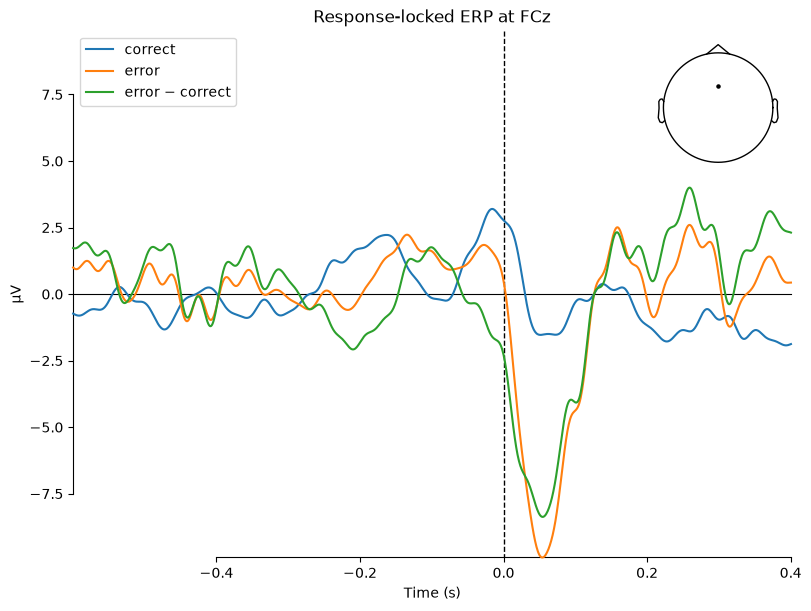

Mean amplitude 0–100 ms at FCz: error -6.39 µV, correct -0.28 µV, ERN (difference) -6.12 µV


In [5]:
# I cut response-locked epochs, drop noisy trials and plot error vs correct averages at FCz
sf = raw.info["sfreq"]
events = np.column_stack([(trials.resp_onset * sf).round().astype(int) + raw.first_samp,
                          np.zeros(len(trials), int), trials.error + 1])
epochs = mne.Epochs(raw, events, event_id={"correct": 1, "error": 2}, tmin=-0.6, tmax=0.4,
                    baseline=(-0.4, -0.2), picks="eeg", reject=dict(eeg=150e-6), preload=True)
keep = np.array([len(log) == 0 for log in epochs.drop_log])
trials = trials[keep].reset_index(drop=True)
print(epochs)

CH = "FCz" if "FCz" in epochs.ch_names else "Cz"
evk = {c: epochs[c].average() for c in ("correct", "error")}
diff = mne.combine_evoked([evk["error"], evk["correct"]], weights=[1, -1])
mne.viz.plot_compare_evokeds({"correct": evk["correct"], "error": evk["error"], "error − correct": diff},
                             picks=CH, title=f"Response-locked ERP at {CH}", show=False)
plt.show()

win = (0.0, 0.1)
mean_amp = lambda e: e.copy().pick(CH).crop(*win).data.mean() * 1e6
print(f"Mean amplitude {int(win[0]*1000)}–{int(win[1]*1000)} ms at {CH}: "
      f"error {mean_amp(evk['error']):.2f} µV, correct {mean_amp(evk['correct']):.2f} µV, "
      f"ERN (difference) {mean_amp(diff):.2f} µV")

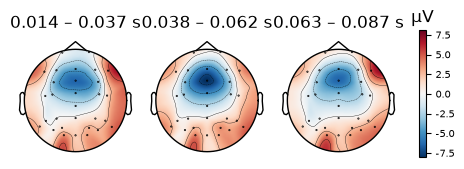

In [6]:
# I map the error-minus-correct difference across the scalp to check the ERN is fronto-central
if raw.get_montage() is not None:
    diff.plot_topomap(times=[0.025, 0.05, 0.075], average=0.025, show=False)
    plt.show()

## 5 Predict errors trial by trial: behaviour vs EEG vs both

An average hides how noisy single trials are. Here a logistic-regression classifier predicts whether **each** response was an error, using:

- **(a) Behaviour**: reaction time and trial type (errors in this task tend to be fast)
- **(b) EEG**: mean voltage in 50 ms windows from −100 to 300 ms at fronto-central sites
- **(c) Both**

Performance is the area under the ROC curve (AUC; 0.5 = chance, 1 = perfect) from 5-fold stratified cross-validation, with class weighting because errors are rare. A permutation test checks whether each AUC beats chance.

In [7]:
# I build behavioural and EEG feature sets and compare cross-validated AUC for each
sites = [c for c in ("Fz", "FCz", "Cz", "FC1", "FC2") if c in epochs.ch_names] or epochs.ch_names[:5]
bins = np.arange(-0.1, 0.3, 0.05)
X_eeg = np.concatenate([epochs.copy().pick(sites).crop(b, b + 0.05).get_data().mean(-1) for b in bins], axis=1) * 1e6
X_beh = trials[["rt", "incompatible"]].astype(float).to_numpy()
y = trials.error.to_numpy()

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG)
model = lambda: make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
sets = {"Behaviour only": X_beh, "EEG only": X_eeg, "Behaviour + EEG": np.hstack([X_beh, X_eeg])}

scores, rng = {}, np.random.default_rng(RNG)
for name, X in sets.items():
    p = cross_val_predict(model(), X, y, cv=cv, method="predict_proba")[:, 1]
    auc = roc_auc_score(y, p)
    null = [roc_auc_score(rng.permutation(y), p) for _ in range(1000)]
    scores[name] = dict(auc=auc, p_value=(np.sum(np.array(null) >= auc) + 1) / 1001, proba=p)
    print(f"{name:16s} AUC = {auc:.3f}   permutation p = {scores[name]['p_value']:.3f}")

Behaviour only   AUC = 0.842   permutation p = 0.001


EEG only         AUC = 0.850   permutation p = 0.001


Behaviour + EEG  AUC = 0.851   permutation p = 0.001


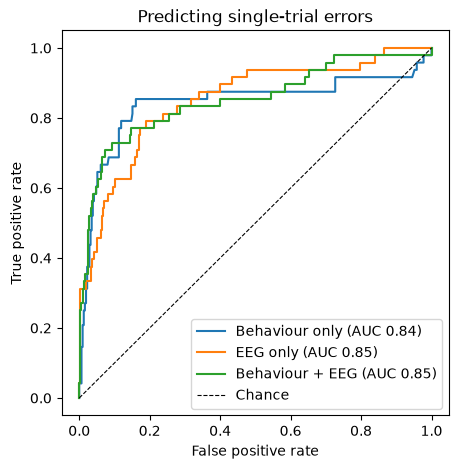

In [8]:
# I plot the ROC curves so the three feature sets can be compared at a glance
fig, ax = plt.subplots(figsize=(5, 5))
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(y, s["proba"])
    ax.plot(fpr, tpr, label=f"{name} (AUC {s['auc']:.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="Chance")
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="Predicting single-trial errors")
ax.legend(loc="lower right")
plt.show()

## 6 What this means for shared agency

Read the results above against the P6 rule in the prototype:

- If **EEG only** beats chance, a single-trial error signal exists, which supports listening to it at all.
- If **Behaviour + EEG** is only a little better than **Behaviour only**, the neural signal should add a *small, capped* amount of risk on top of behavioural and evidence checks, not decide by itself. That is the P6 rule's design.
- One participant and a simple, fast task is a limited test: search decisions are slower and messier. Scaling this to many participants, with participant-level cross-validation, and to search events (choosing a source, deciding to stop) is exactly the work proposed in Study 1 of the PhD.

**Reference:** Kappenman, E. S., Farrens, J. L., Zhang, W., Stewart, A. X. and Luck, S. J. (2021). ERP CORE: An open resource for human event-related potential research. *NeuroImage*, 225, 117465.